In [12]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import features as rf
from matplotlib import pyplot as plt
from pathlib import Path

In [4]:
country_raster_1km_ = rio.open(r'../results/country-rasters/country-raster-eck4-1km.tif')
country_raster_10km_ = rio.open(r'../results/country-rasters/country-raster-eck4-10km.tif')
country_raster_50km_ = rio.open(r'../results/country-rasters/country-raster-eck4-50km.tif')

In [5]:
TEOW = gpd.read_file(r'../data/TEOW/wwf_terr_ecos.shp')

In [6]:
TEOW['BIOME'].value_counts()

BIOME
1.0     4187
11.0    2513
14.0    1483
4.0     1300
5.0     1047
13.0     686
7.0      597
3.0      519
12.0     479
10.0     428
6.0      427
2.0      357
9.0      182
8.0      146
99.0      82
98.0      25
Name: count, dtype: int64

In [7]:
TEOW_eck4 = TEOW.to_crs('ESRI:54012')

In [8]:
biome_shapes_eck4 = []
for i in TEOW.index:
    biome_value = TEOW.loc[i, 'BIOME']
    a_shape = TEOW.loc[i, 'geometry']
    b_shape = TEOW_eck4.loc[i, 'geometry']
    biome_shapes_eck4.append((b_shape, biome_value))

In [9]:
biome_rst_1km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_1km_.shape, 
                             fill=0, 
                             transform=country_raster_1km_.transform,)

In [10]:
biome_rst_10km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_10km_.shape, 
                             fill=0, 
                             transform=country_raster_10km_.transform,)

In [11]:
biome_rst_50km = rf.rasterize(shapes=biome_shapes_eck4, 
                             out_shape=country_raster_50km_.shape, 
                             fill=0, 
                             transform=country_raster_50km_.transform,)

display results

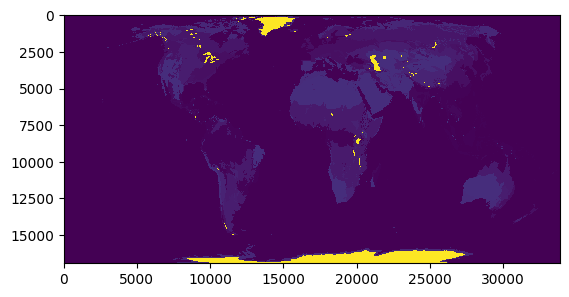

In [12]:
plt.imshow(biome_rst_1km, interpolation='nearest')
plt.show()

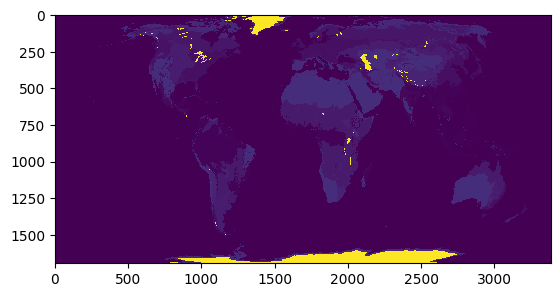

In [14]:
plt.imshow(biome_rst_10km, interpolation='nearest')
plt.show()

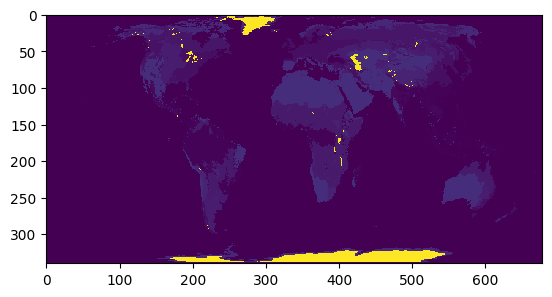

In [15]:
plt.imshow(biome_rst_50km, interpolation='nearest')
plt.show()

output results

In [13]:
Path(r'../results/biome-rasters').mkdir(parents=True, exist_ok=True)

In [ ]:
with rio.open(
    r'../results/biome-rasters/biome-raster-eck4-1km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_1km.shape[0],
    width=biome_rst_1km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_1km_.crs,
    transform=country_raster_1km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_1km, 1)

In [ ]:
with rio.open(
    r'../results/biome-rasters/biome-raster-eck4-10km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_10km.shape[0],
    width=biome_rst_10km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_10km_.crs,
    transform=country_raster_10km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_10km, 1)

In [ ]:
with rio.open(
    r'../results/biome-rasters/biome-raster-eck4-50km.tif',
    'w',
    driver='GTiff',
    height=biome_rst_50km.shape[0],
    width=biome_rst_50km.shape[1],
    count=1,
    dtype=np.uint8, 
    crs=country_raster_50km_.crs,
    transform=country_raster_50km_.transform,
    compress='lzw',
) as dst:
    dst.write(biome_rst_50km, 1)

In [ ]:
# 1: 'Tropical and Subtropical Moist Broadleaf Forests',
# 2: 'Tropical and Subtropical Dry Broadleaf Forests',
# 3: 'Tropical and Subtropical Coniferous Forests',
# 4: 'Temperate Broadleaf and Mixed Forests',
# 5: 'Temperate Coniferous Forests',
# 6: 'Boreal Forests/Taiga',
# 7: 'Tropical and Subtropical Grasslands, Savannas and Shrublands',
# 8: 'Temperate Grasslands, Savannas and Shrublands',
# 9: 'Flooded Grasslands and Savannas',
# 10: 'Montane Grasslands and Shrublands',
# 11: 'Tundra',
# 12: 'Mediterranean Forests, Woodlands and Scrub',
# 13: 'Deserts and Xeric Shrublands',
# 14: 'Mangroves'